<center>
    <img src="https://s3-api.us-geo.objectstorage.softlayer.net/cf-courses-data/CognitiveClass/Logos/organization_logo/organization_logo.png" width="300" alt="cognitiveclass.ai logo">
</center>


#### Import the required libraries we need for the lab.


In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as pyplot
import scipy.stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

In [5]:
# Seaborn đã được cài đặt sẵn trong Google Colab.
# Nếu cần cài đặt thư viện khác, hãy dùng !pip thay vì micropip:
!pip install seaborn

#### Read the dataset in the csv file from the URL


In [6]:
boston_df=pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv')

#### Add your code below following the instructions given in the course to complete the peer graded assignment


,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,4.98,24.0
1,1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,9.14,21.6
2,2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,4.03,34.7
3,3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,2.94,33.4
4,4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,5.33,36.2


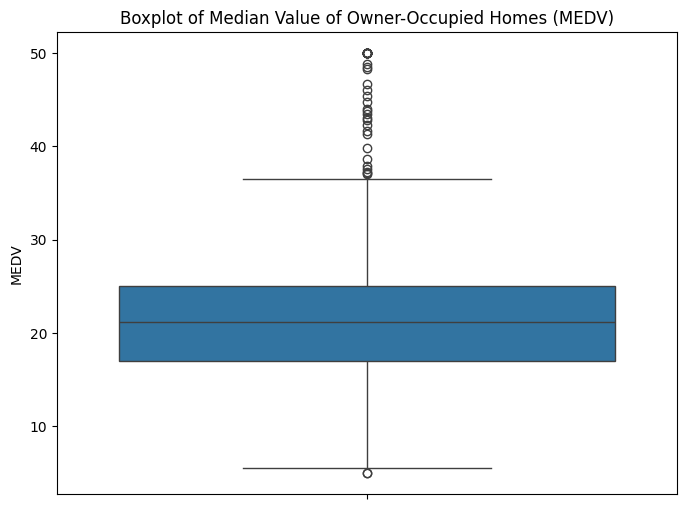

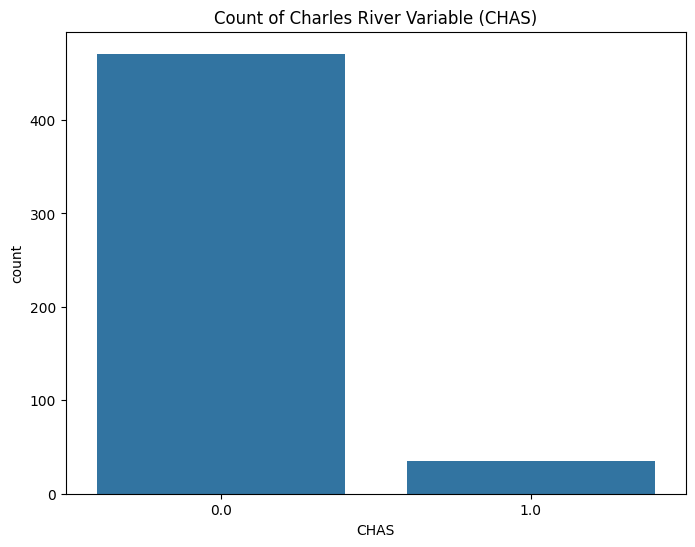

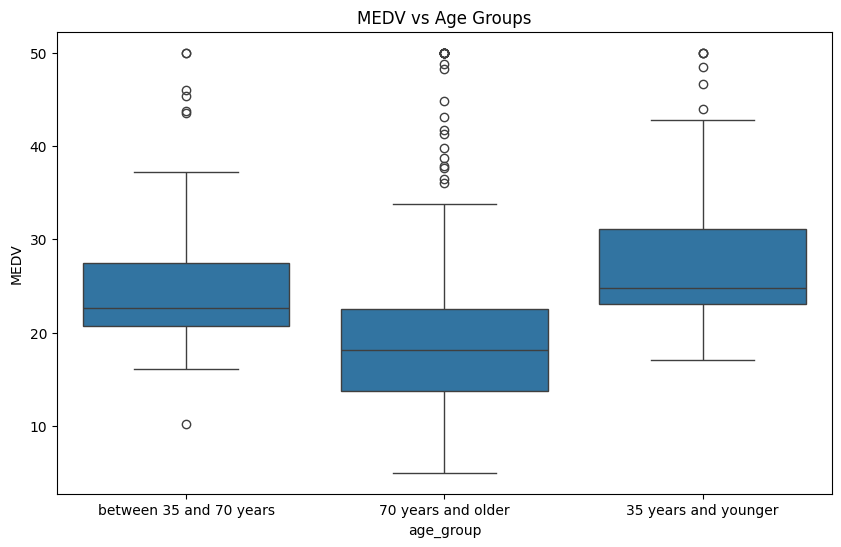

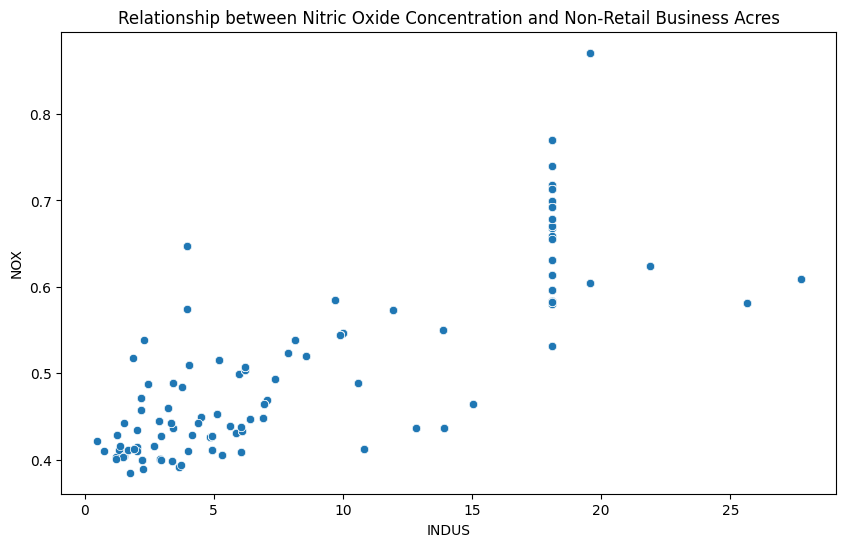

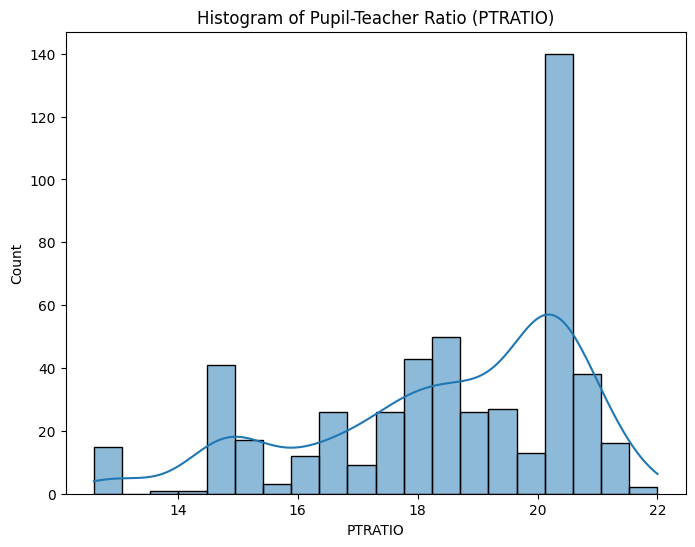

T-test (CHAS vs MEDV): TtestResult(statistic=np.float64(3.996437466090509), pvalue=np.float64(7.390623170519905e-05), df=np.float64(504.0))
ANOVA results (Age Groups vs MEDV): F-statistic = 36.40764999196598 , p-value = 1.7105011022702984e-15
Pearson correlation (NOX vs INDUS): PearsonRResult(statistic=np.float64(0.7636514469209154), pvalue=np.float64(7.913361061239639e-98))
                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           1.21e-08
Time:                        14:47:49   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                         

In [7]:
# 1. Display the first few rows of the dataset to verify loading
display(boston_df.head())

# 2. Boxplot for the "Median value of owner-occupied homes" (MEDV)
pyplot.figure(figsize=(8, 6))
sns.boxplot(y='MEDV', data=boston_df)
pyplot.title('Boxplot of Median Value of Owner-Occupied Homes (MEDV)')
pyplot.show()

# 3. Histogram / Count plot for the Charles River variable (CHAS)
pyplot.figure(figsize=(8, 6))
sns.countplot(x='CHAS', data=boston_df)
pyplot.title('Count of Charles River Variable (CHAS)')
pyplot.show()

# 4. Boxplot for MEDV vs AGE (discretized AGE into three groups)
boston_df.loc[boston_df['AGE'] <= 35, 'age_group'] = '35 years and younger'
boston_df.loc[(boston_df['AGE'] > 35) & (boston_df['AGE'] < 70), 'age_group'] = 'between 35 and 70 years'
boston_df.loc[boston_df['AGE'] >= 70, 'age_group'] = '70 years and older'

pyplot.figure(figsize=(10, 6))
sns.boxplot(x='age_group', y='MEDV', data=boston_df)
pyplot.title('MEDV vs Age Groups')
pyplot.show()

# 5. Scatter plot to show the relationship between NOX (Nitric oxides concentration) and INDUS (non-retail business acres)
pyplot.figure(figsize=(10, 6))
sns.scatterplot(x='INDUS', y='NOX', data=boston_df)
pyplot.title('Relationship between Nitric Oxide Concentration and Non-Retail Business Acres')
pyplot.show()

# 6. Histogram for the pupil-to-teacher ratio (PTRATIO)
pyplot.figure(figsize=(8, 6))
sns.histplot(boston_df['PTRATIO'], bins=20, kde=True)
pyplot.title('Histogram of Pupil-Teacher Ratio (PTRATIO)')
pyplot.show()

# --- Statistical Testing & Modeling ---

# 7. T-test: Is there a significant difference in median value of houses bounded by the Charles river or not?
charles_yes = boston_df[boston_df['CHAS'] == 1]['MEDV']
charles_no = boston_df[boston_df['CHAS'] == 0]['MEDV']
t_test_res = scipy.stats.ttest_ind(charles_yes, charles_no)
print("T-test (CHAS vs MEDV):", t_test_res)

# 8. ANOVA: Is there a difference in Median values of houses (MEDV) across the AGE groups?
f_stat, p_val = scipy.stats.f_oneway(
    boston_df[boston_df['age_group'] == '35 years and younger']['MEDV'],
    boston_df[boston_df['age_group'] == 'between 35 and 70 years']['MEDV'],
    boston_df[boston_df['age_group'] == '70 years and older']['MEDV']
)
print("ANOVA results (Age Groups vs MEDV): F-statistic =", f_stat, ", p-value =", p_val)

# 9. Pearson Correlation: Relationship between Nitric Oxide concentrations (NOX) and non-retail business acres (INDUS)
pearson_corr = scipy.stats.pearsonr(boston_df['NOX'], boston_df['INDUS'])
print("Pearson correlation (NOX vs INDUS):", pearson_corr)

# 10. Regression Analysis: Impact of weighted distance to employment centres (DIS) on median home values (MEDV)
X = sm.add_constant(boston_df['DIS'])
y = boston_df['MEDV']
regression_model = sm.OLS(y, X).fit()
print(regression_model.summary())